# Student Lifestyle and Academic Performance


## Loading the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Time-use columns (each student's five activities sum to 24 hours)
TIME_COLS = [
    "Study_Hours_Per_Day",
    "Extracurricular_Hours_Per_Day",
    "Sleep_Hours_Per_Day",
    "Social_Hours_Per_Day",
    "Physical_Activity_Hours_Per_Day",
]

sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e6e6", "axes.edgecolor": "#444444"})

# ---- Colour palette used by every chart in this notebook ----                                  # 0 = Low, 1 = Medium, 2 = High
STRESS_PALETTE = {0: "#2a9d8f", 1: "#e9c46a", 2: "#e76f51"}  # teal, sand, coral
COLUMN_COLOR = {
    "Study_Hours_Per_Day": "#355070",                        # navy
    "Extracurricular_Hours_Per_Day": "#e56b6f",              # rose
    "Sleep_Hours_Per_Day": "#6d597a",                        # plum
    "Social_Hours_Per_Day": "#b56576",                       # mauve
    "Physical_Activity_Hours_Per_Day": "#eaac8b",            # peach
    "CGPA": "#2a9d8f",                                       # teal
}

In [2]:
df = pd.read_csv("student_lifestyle_dataset.csv")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
display(df.head())

Rows: 2,000
Columns: 8
Missing values: 0
Duplicate rows: 0


,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,CGPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,1
1,2,5.3,3.5,8.0,4.2,3.0,2.75,0
2,3,5.1,3.9,9.2,1.2,4.6,2.67,0
3,4,6.5,2.1,7.2,1.7,6.5,2.88,1
4,5,8.1,0.6,6.5,2.2,6.6,3.51,2


In [3]:
display(df.drop(columns="Student_ID").describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Study_Hours_Per_Day,2000.0,7.48,1.42,5.00,6.3,7.40,8.70,10.0
Extracurricular_Hours_Per_Day,2000.0,1.99,1.16,0.00,1.0,2.00,3.00,4.0
Sleep_Hours_Per_Day,2000.0,7.50,1.46,5.00,6.2,7.50,8.80,10.0
Social_Hours_Per_Day,2000.0,2.70,1.69,0.00,1.2,2.60,4.10,6.0
Physical_Activity_Hours_Per_Day,2000.0,4.33,2.51,0.00,2.4,4.10,6.10,13.0
CGPA,2000.0,3.12,0.30,2.24,2.9,3.11,3.33,4.0
Stress_Level,2000.0,1.37,0.73,0.00,1.0,2.00,2.00,2.0


## Stress levels

Comparing the number of students in each stress group.

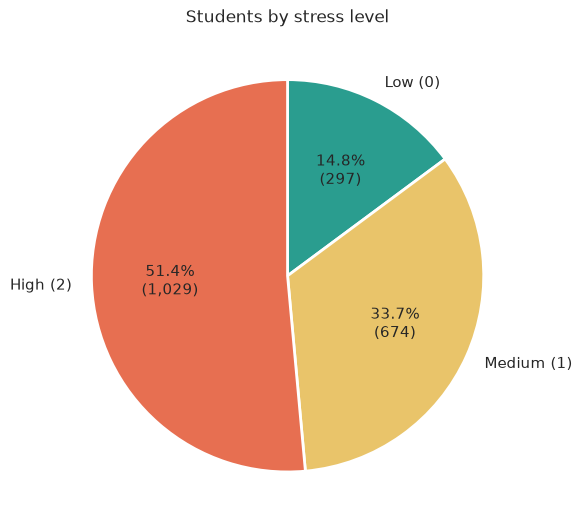

In [4]:
stress_counts = df["Stress_Level"].value_counts().reindex([0, 1, 2])
stress_labels = ["Low (0)", "Medium (1)", "High (2)"]

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    stress_counts,
    labels=stress_labels,
    autopct=lambda p: f"{p:.1f}%\n({round(p * stress_counts.sum() / 100):,})",
    startangle=90,
    counterclock=False,
    colors=[STRESS_PALETTE[s] for s in [0, 1, 2]],
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
)
ax.set_title("Students by stress level")
plt.tight_layout()
plt.show()

## Daily routines

These charts show how the reported hours and GPA are spread across the students in the dataset.

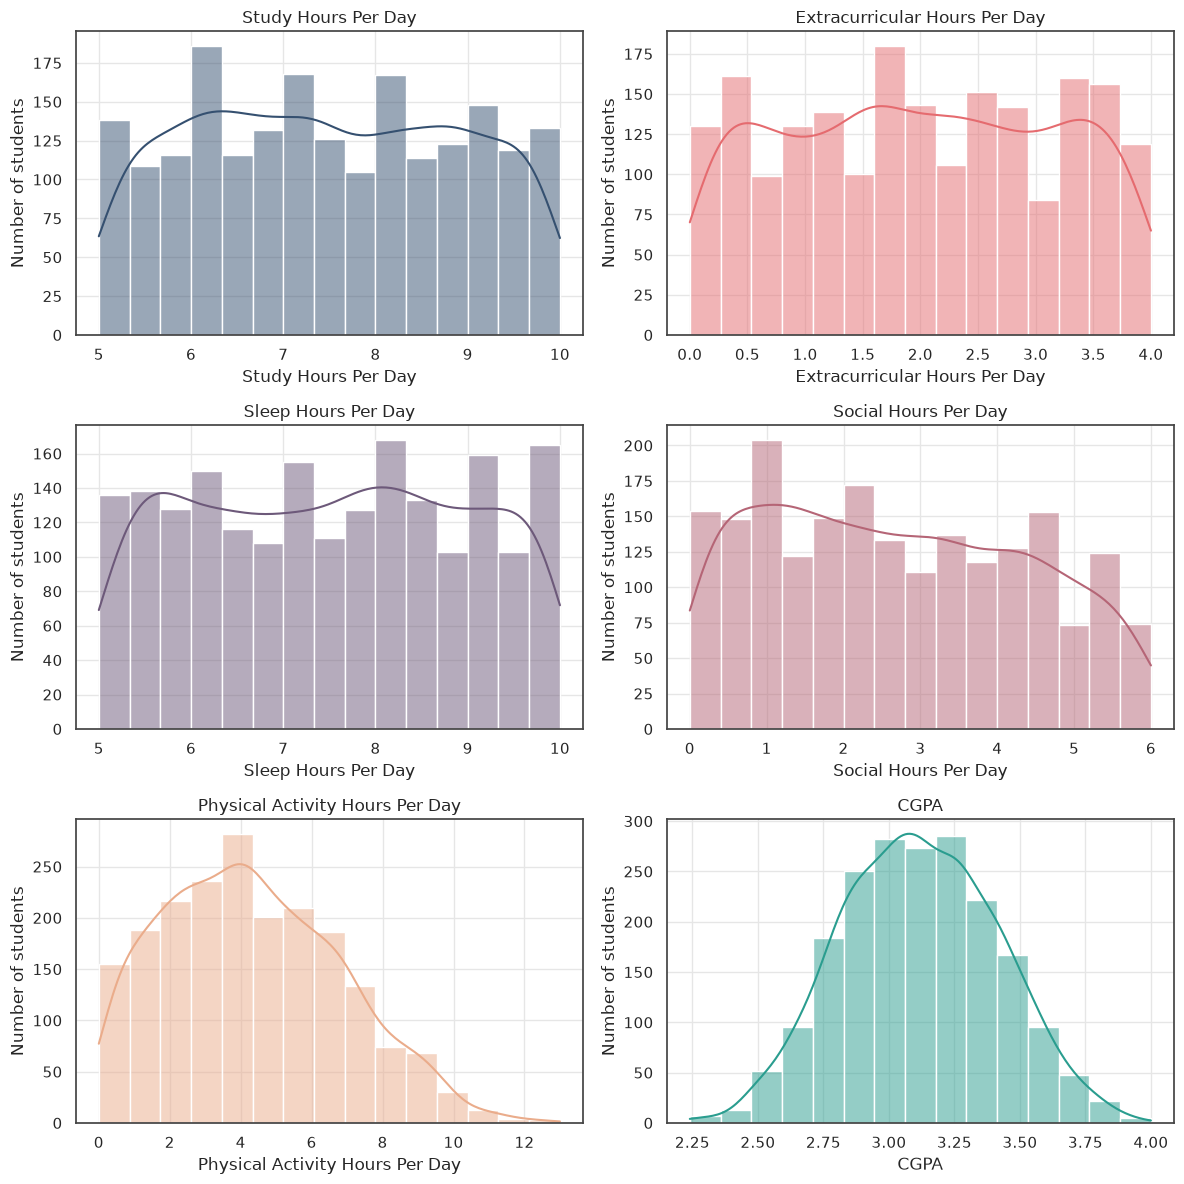

In [5]:
columns_to_plot = TIME_COLS + ["CGPA"]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for ax, column in zip(axes.flat, columns_to_plot):
    label = column.replace("_", " ")
    sns.histplot(data=df, x=column, bins=15, kde=True, color=COLUMN_COLOR[column], edgecolor="white", ax=ax)
    ax.set(title=label, xlabel=label, ylabel="Number of students")

plt.tight_layout()
plt.show()


# CGPA and Stress

Comparing CGPA across the three stress groups. The box plots show the full distribution and spread of scores, not just the overall average.

**Note about box plots:**

1. **Median (50th Percentile):** The horizontal line inside the box marks the middle value ($Q2$).
2. **Third Quartile (75th Percentile):** The top boundary of the box marks $Q3$ (upper 75% threshold).
3. **First Quartile (25th Percentile):** The bottom boundary of the box marks $Q1$ (lower 25% threshold).
4. The Interquartile range is defined as $\text{IQR} = Q3 - Q1$.
5. **Lower Whisker:** Extends to the smallest data value that is greater than or equal to $Q1 - 1.5 \times \text{IQR}$.
6. **Upper Whisker:** Extends to the largest data value that is less than or equal to $Q3 + 1.5 \times \text{IQR}$.
7. **Outliers:** Any data points plotted beyond the whiskers fall outside the $1.5 \times \text{IQR}$ range.

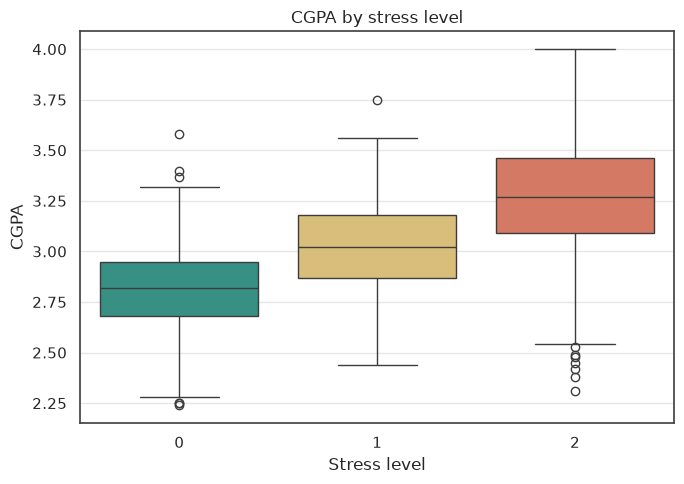

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="Stress_Level",
    y="CGPA",
    hue="Stress_Level",
    palette=STRESS_PALETTE,
    legend=False,
    ax=ax,
)
ax.set(title="CGPA by stress level", xlabel="Stress level", ylabel="CGPA")
plt.tight_layout()
plt.show()

## Daily routines by stress level

Compare study, sleep, activity, social, and extracurricular hours across stress groups.

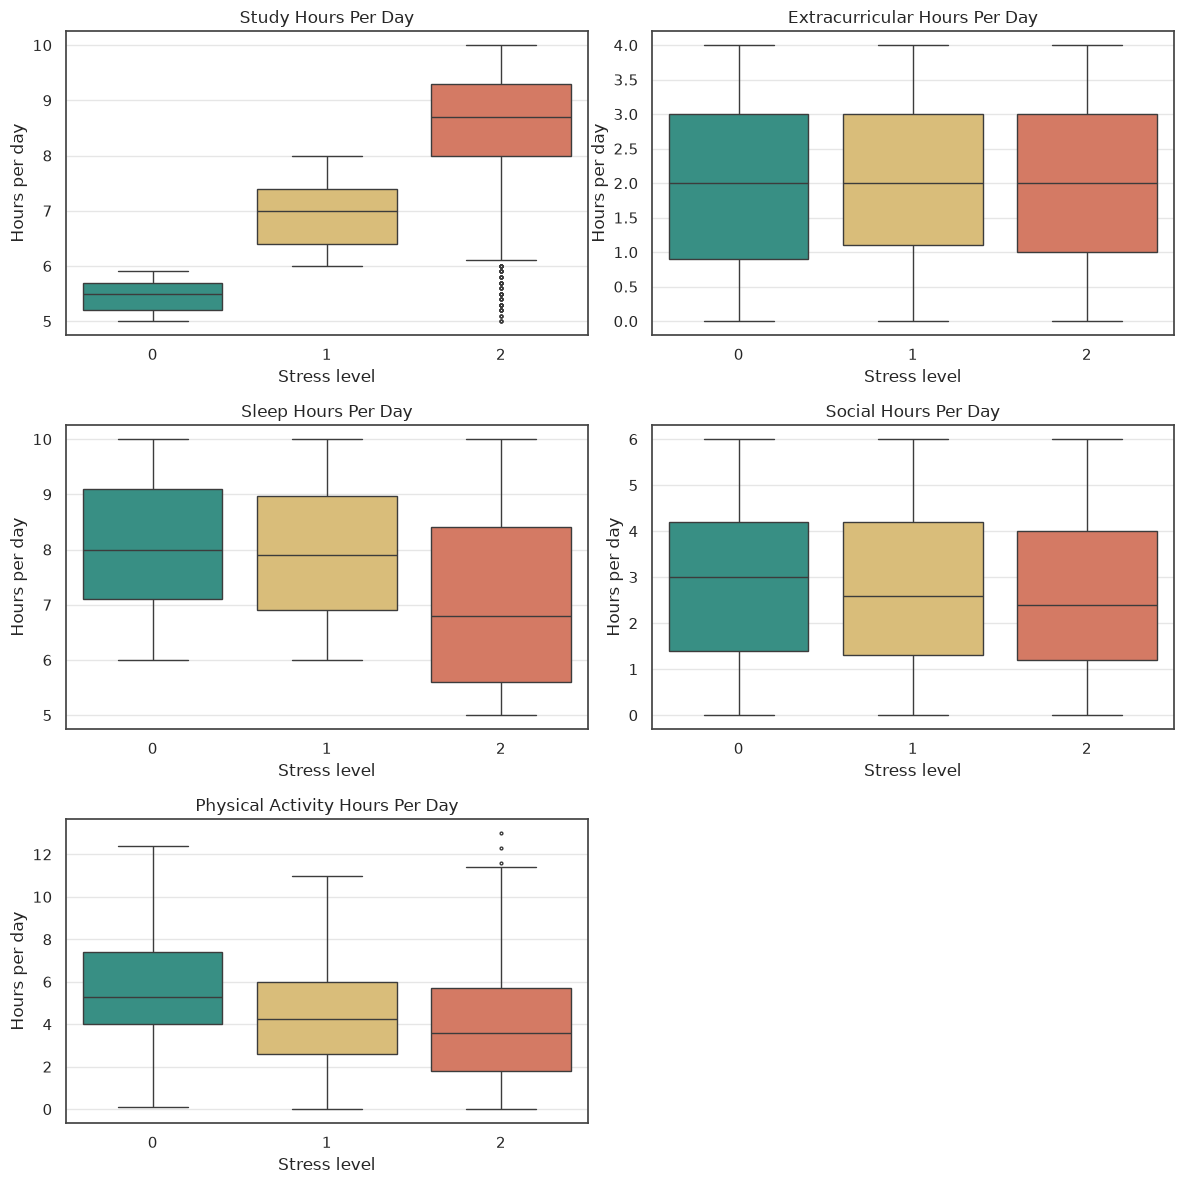

In [7]:
routine_columns = TIME_COLS

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for ax, column in zip(axes.flat, routine_columns):
    label = column.replace("_", " ")
    sns.boxplot(
        data=df,
        x="Stress_Level",
        y=column,
        hue="Stress_Level",
        palette=STRESS_PALETTE,
        legend=False,
        fliersize=2,
        ax=ax,
    )
    ax.set(title=label, xlabel="Stress level", ylabel="Hours per day")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()


## Group averages and CGPA relationships

The averages make it easier to compare the stress groups. The correlations describe how two numeric columns vary together in this dataset.

In [8]:
group_averages = (
    df.groupby("Stress_Level")[["CGPA", *TIME_COLS]]
    .mean()
    .round(2)
)
display(group_averages)


,CGPA,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day
Stress_Level,,,,,,
0,2.82,5.47,1.99,8.06,2.89,5.58
1,3.02,6.97,2.01,7.95,2.74,4.34
2,3.26,8.39,1.98,7.05,2.63,3.96


## Correlation analysis

The code below generates a correlation heatmap.

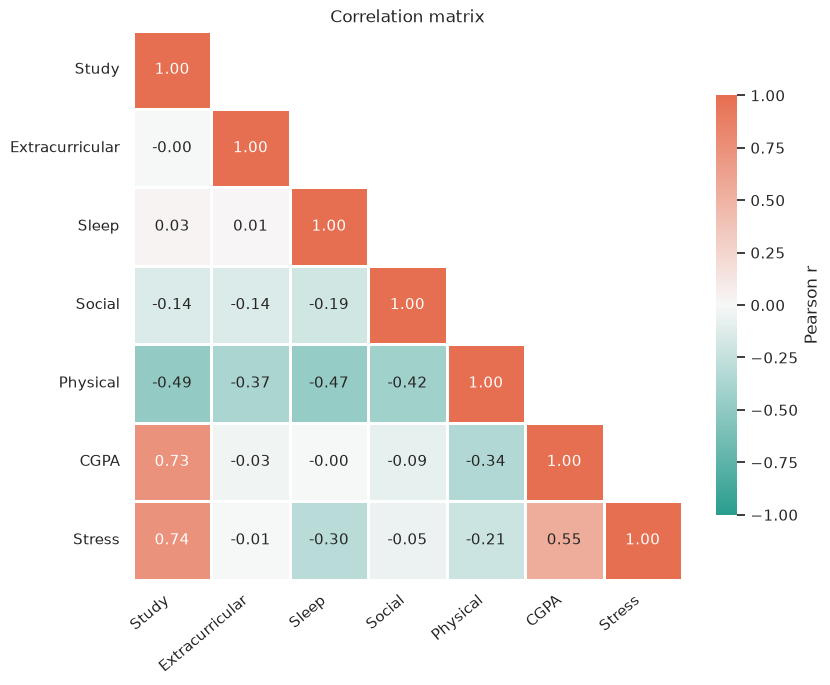

In [9]:
LABEL = {
    "Study_Hours_Per_Day": "Study",
    "Extracurricular_Hours_Per_Day": "Extracurricular",
    "Sleep_Hours_Per_Day": "Sleep",
    "Social_Hours_Per_Day": "Social",
    "Physical_Activity_Hours_Per_Day": "Physical",
    "Stress_Level": "Stress",
}

cols = TIME_COLS + ["CGPA", "Stress_Level"]
corr = df[cols].corr().rename(index=LABEL, columns=LABEL)  # correlation between every pair of variables
k = len(corr)
mask = pd.DataFrame([[j > i for j in range(k)] for i in range(k)], index=corr.index, columns=corr.columns)  # hide the upper triangle

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(                                                # heatmap generation
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap=sns.blend_palette(["#2a9d8f", "#f7f7f7", "#e76f51"], as_cmap=True),
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=2,
    linecolor="white",
    square=True,
    annot_kws={"fontsize": 11},
    cbar_kws={"shrink": 0.75, "label": "Pearson r"},
    ax=ax,
)
ax.grid(False)
ax.set_title("Correlation matrix")
ax.tick_params(axis="x", rotation=40)
plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout()
plt.show()

## Effect of the 24-hour constraint

Every student's five time variables sum to exactly 24 hours, so the data is compositional: any increase in one activity must be offset by a decrease in at least one other. Consequences:

1. **Correlations between time variables are partly mechanical.** They are partly forced by the 24-hour total, so a negative relationship does not necessarily mean students actively choose one activity over another.
2. **Only 4 degrees of freedom.** The five time columns span a 4-dimensional space.
3. **Regression must drop one time column.** Because the five time columns always add up to 24, any one of them can be computed exactly from the other four:

$$\text{Sleep} = 24 - \text{Study} - \text{Extracurricular} - \text{Social} - \text{Physical}$$


In [10]:
# Extract each unique off-diagonal pair and rank by absolute correlation.
pair_values = (
    corr.where(pd.DataFrame([[i > j for j in range(len(corr))] for i in range(len(corr))], index=corr.index, columns=corr.columns))
    .stack()
    .rename("r")
    .reset_index()
)
pair_values.columns = ["Variable 1", "Variable 2", "r"]
pair_values["Pair"] = pair_values["Variable 1"] + " – " + pair_values["Variable 2"]
strongest_pairs = (
    pair_values.assign(abs_r=pair_values["r"].abs())
    .sort_values("abs_r", ascending=False)
    .head(9)[["Pair", "r"]]
    .reset_index(drop=True)
)
display(strongest_pairs.round(2))


,Pair,r
0,Stress – Study,0.74
1,CGPA – Study,0.73
2,Stress – CGPA,0.55
3,Physical – Study,-0.49
4,Physical – Sleep,-0.47
5,Physical – Social,-0.42
6,Physical – Extracurricular,-0.37
7,CGPA – Physical,-0.34
8,Stress – Sleep,-0.30


### Strongest pairs

The table is generated directly from the correlation matrix, so the pairs and their order stay consistent with the heatmap.

### Conclusions from the correlation analysis

These conclusions describe linear associations in this dataset.

- **Study hours has the strongest relationships.** It is strongly positively correlated with both CGPA (0.73) and Stress (0.74).
- **CGPA and Stress are moderately correlated (0.55).** Students with higher CGPA also tend to report higher stress in this data.
- **Extracurricular and Social hours show almost no linear relationship** with CGPA or Stress (|r| ≤ 0.09 in all four pairs).
- **Physical activity has a moderate negative correlation with CGPA (−0.34).** It is also negatively correlated with Stress (−0.21).
- **Sleep has a moderate negative correlation with Stress (−0.30)** and almost zero correlation with CGPA (−0.004).

These are observational correlations, so they do not establish that any lifestyle factor causes a change in CGPA.


## Linear regression

CGPA is regressed on Study, Extracurricular, Social and Physical activity hours using the normal equations, $\beta = (X^\top X)^{-1} X^\top y$, with the matrix inverse computed by `scipy.linalg`.

Sleep is omitted because of the 24-hour constraint described above.


In [11]:
from scipy import linalg

features = ["Study_Hours_Per_Day","Extracurricular_Hours_Per_Day","Social_Hours_Per_Day","Physical_Activity_Hours_Per_Day"]
y = df["CGPA"].to_numpy()

X = df[features].copy()
X.insert(0, "Intercept", 1)                # first column of 1s = intercept
X = X.to_numpy()

XtX = X.T @ X
Xty = X.T @ y

XtX_inv = linalg.inv(XtX)
beta = XtX_inv @ Xty                      # beta = (X^T X)^-1 X^T y



In [12]:
# ---- 1. Coefficients table ----
coef_table = pd.DataFrame(
    {"Coefficient": beta.round(4)},
    index=["Intercept (b0)", "Study hours", "Extracurricular hours", "Social hours", "Physical activity hours"],
)
display(coef_table)

# ---- 2. R² calculation, step by step ----
y_pred = X @ beta                          # predicted CGPA for every student
y_mean = y.mean()                          # CGPA if we just guessed the average for everyone

SST = ((y - y_mean) ** 2).sum()            # total variation in CGPA
SSE = ((y - y_pred) ** 2).sum()            # error left after using the regression
R2 = 1 - SSE / SST

print(f"Mean CGPA          = {y_mean:.4f}")
print(f"SST = Σ(y − mean)² = {SST:.3f}   (total variation)")
print(f"SSE = Σ(y − pred)² = {SSE:.3f}   (error left over)")
print(f"R² = 1 − SSE/SST   = 1 − {SSE / SST:.3f} = {R2:.3f}")

,Coefficient
Intercept (b0),1.8981
Study hours,0.1589
Extracurricular hours,-0.0029
Social hours,0.0059
Physical activity hours,0.0045


Mean CGPA          = 3.1160
SST = Σ(y − mean)² = 178.323   (total variation)
SSE = Σ(y − pred)² = 81.856   (error left over)
R² = 1 − SSE/SST   = 1 − 0.459 = 0.541


### Conclusions from the regression

- **Study hours is the only feature that contributes meaningfully to the model's in-sample explanatory power.** Its coefficient is approximately 0.159 CGPA points per extra study hour. The Extracurricular, Social and Physical coefficients are all tiny (|b| ≤ 0.006 per hour). Study hours alone gives nearly the same fit as the full model (R² = 0.734² ≈ 0.539 versus R² = 0.541).
- **Physical activity's negative raw correlation with CGPA (−0.34) largely disappears once Study is included in the model** (coefficient ≈ 0.005). Study and Physical activity are themselves negatively correlated (−0.49), so their shared variation helps explain the difference between the raw correlation and the regression coefficient.
- **Interpret coefficients in light of the 24-hour constraint:** because Sleep is the omitted column, each coefficient represents reallocating one hour from Sleep to that activity, holding the other included activities constant.

### What Goodness-of-Fit Measure R² = 0.541 Means

- CGPA differs from student to student. The total sum of squares (SST) measures this variation around the average CGPA. It represents the total variation to be explained and the error made by predicting the mean CGPA for everyone.
- The regression predicts each student's CGPA using their activity hours. The remaining prediction errors add up to the sum of squared errors (SSE).
- R² = 1 − SSE / SST = 1 − 0.459 = 0.541. The model explains about 54% of the variation in CGPA, leaving about 46% unexplained.
- For example, two students who both study 7 hours a day receive the same prediction, say 3.0, but their actual CGPAs may be 2.8 and 3.3.
- Other factors, such as prior academic performance, course difficulty, ability or attendance, could help explain some of the remaining variation. However, these factors are not included in the dataset, so their individual contributions cannot be established from this regression.


## Additional analysis: Central Limit Theorem simulation

This section is not part of the main project question. It is included just for fun, to check the Central Limit Theorem (CLT) on the dataset.

### Simulation setup

Study hours is used for the simulation because its distribution looks far from normal. For each sample size $n$, 5,000 samples are drawn and the table compares the sample means with the CLT prediction.

In [13]:
from scipy import stats
variable = "Study_Hours_Per_Day"
population = df[variable]
mu, sigma = population.mean(), population.std(ddof=0)

sample_sizes = [1, 2, 5, 10, 30, 100]
n_samples = 5000

def draw_sample_means(n):
    # draw n_samples * n values with replacement, then average each consecutive block of n values
    draws = population.sample(n=n_samples * n, replace=True, random_state=0).reset_index(drop=True)
    return draws.groupby(draws.index // n).mean()

sample_means = {n: draw_sample_means(n) for n in sample_sizes}

rows = []
for n, means in sample_means.items():
    expected_sd = sigma / n ** 0.5
    rows.append({
        "n": n,
        "Mean of sample means": means.mean(),
        "SD of sample means": means.std(ddof=1),
        "CLT SD (sigma/sqrt(n))": expected_sd,
        "Skewness": stats.skew(means),
    })

print(f"Population mean: {mu:.4f}   Population SD: {sigma:.4f}")
display(pd.DataFrame(rows).set_index("n").round(4))

Population mean: 7.4758   Population SD: 1.4235


,Mean of sample means,SD of sample means,CLT SD (sigma/sqrt(n)),Skewness
n,,,,
1,7.4635,1.4298,1.4235,0.0556
2,7.4444,1.0029,1.0066,0.0348
5,7.4635,0.6407,0.6366,0.0921
10,7.4747,0.4484,0.4502,0.0323
30,7.4768,0.2584,0.2599,-0.0077
100,7.4764,0.1426,0.1424,-0.0008


### Distribution of sample means

Each panel shows the sample means for one sample size, with the CLT normal curve $N(\mu, \sigma^2/n)$ as a dashed line.

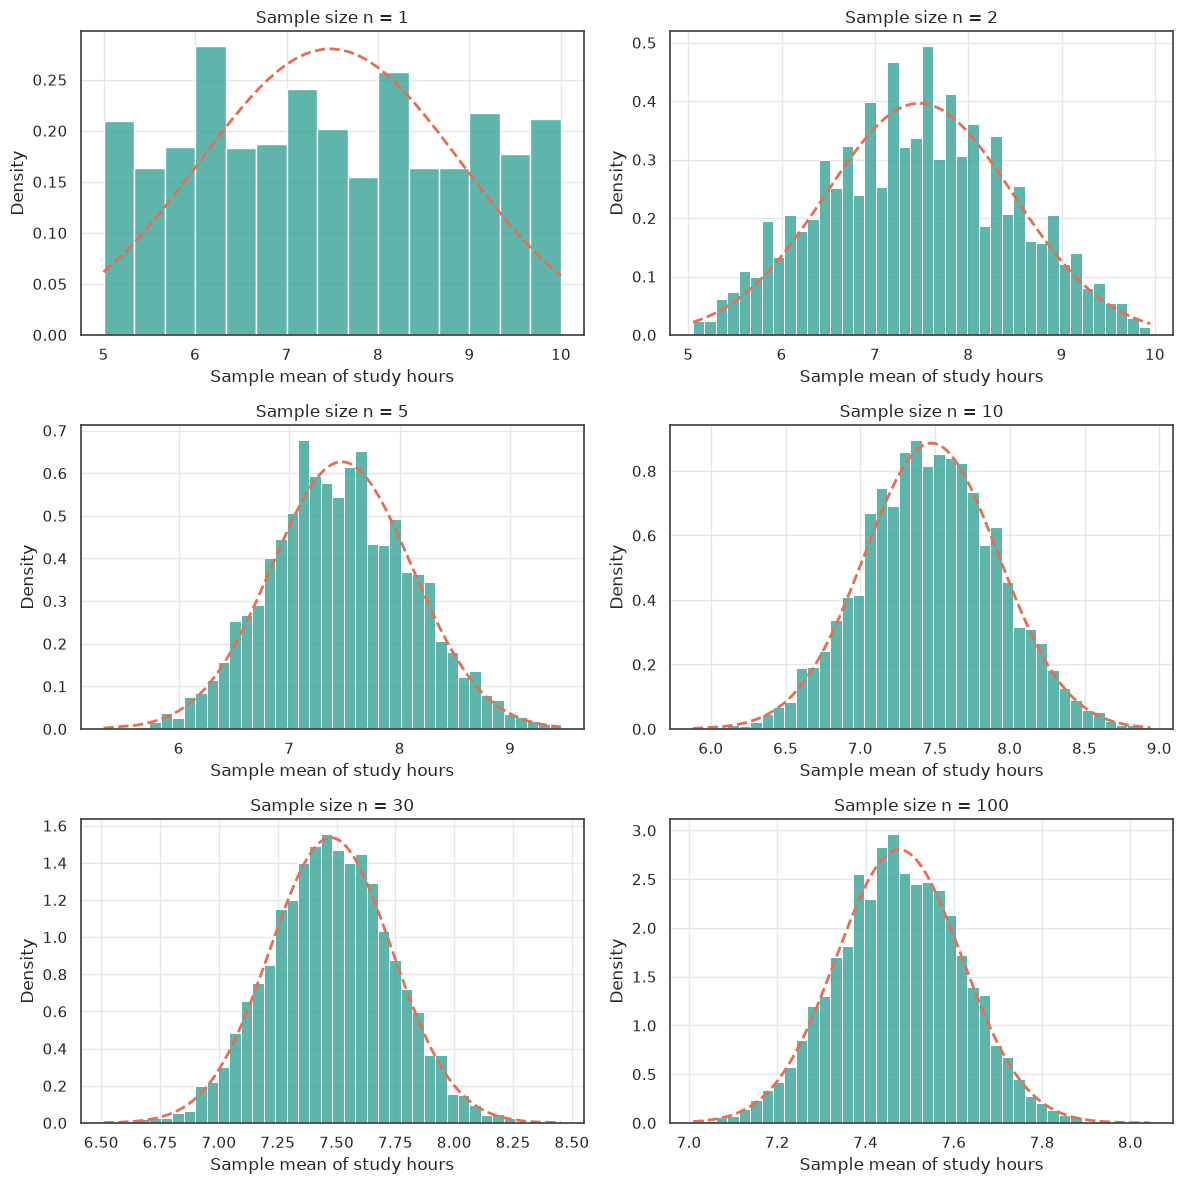

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for ax, n in zip(axes.flat, sample_sizes):
    means = sample_means[n]
    sns.histplot(means, bins=15 if n == 1 else 40, stat="density", color="#2a9d8f", edgecolor="white", ax=ax)
    xs = means.sort_values()                      # evaluate the normal curve at the sorted sample means
    ax.plot(xs, stats.norm.pdf(xs, mu, sigma / n ** 0.5), "--", color="#e76f51", lw=2)
    ax.set(title=f"Sample size n = {n}", xlabel="Sample mean of study hours", ylabel="Density")

plt.tight_layout()
plt.show()


## Observations from the CLT simulation

The standard deviation of the sample means decreases as the sample size grows and closely tracks the theoretical value $\sigma/\sqrt{n}$ in the table. The sample-mean skewness stays close to zero across the tested sample sizes (about −0.035 to 0.077); it does not show a steady decrease in this particular simulation.